<a href="https://colab.research.google.com/github/DariiaIvanova23/ml-lab-4/blob/main/ml_lab_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4
## Дослідження дерев рішень та ансамблевих методів у задачі багатокласової класифікації за наявності пропущених значень

**Виконала:** Іванова Дарія Феі-44  

### Мета роботи:
Дослідити та порівняти три алгоритми класифікації: дерево рішень (*Decision Tree*), випадковий ліс (*Random Forest*) та градієнтний бустинг (*XGBoost*) на датасеті **Annealing** з пропущеними даними. Дослідити вплив індикаторів пропусків, коректного тюнінгу гіперпараметрів через **Optuna** (вкладена крос-валідація), провести статистичне порівняння скоригованим $t$-тестом Наде–Бенжіо та інтерпретувати моделі за допомогою MDI, Permutation Importance та SHAP.

In [ ]:
# Встановлення необхідних версій бібліотек
!pip install -q scikit-learn>=1.4 xgboost>=2.0 optuna>=3.0 shap>=0.44

import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

from sklearn.datasets import fetch_openml
from sklearn.model_selection import (
    train_test_split,
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_validate,
    cross_val_score,
    cross_val_predict
)
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.inspection import permutation_importance

from xgboost import XGBClassifier
import optuna
import shap

# Фіксація SEED
SEED = 45
np.random.seed(SEED)
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Збереження версій
print(f"Python: {sys.version.split()[0]}")
import sklearn, xgboost
print(f"scikit-learn: {sklearn.__version__}")
print(f"xgboost: {xgboost.__version__}")
print(f"optuna: {optuna.__version__}")
print(f"shap: {shap.__version__}")

Python: 3.13.16
scikit-learn: 1.9.1
xgboost: 3.4.1
optuna: 5.0.0
shap: 0.54.1


## 3.1. Первинний аналіз даних

У цьому розділі виконується:
1. Завантаження датасету **Annealing** (OpenML ID: `anneal`, version 1, 898 спостережень).
2. Приведення категоріальних ознак до типу `object`.
3. Очищення від константних ознак та ознак, що на $100\%$ складаються з пропусків.
4. Аналіз розподілу класів цільової змінної $y$. Виявлення ультра-рідкісних класів.
   > Якщо клас містить критично малу кількість прикладів (наприклад, $\le 3$), він не зможе бути коректно розбитий на стратифіковані фолди у внутрішній 3-блочній крос-валідації ($K_{\text{inner}}=3$). Тому спостереження класів із кількістю екземплярів $< 5$ доцільно вилучити або об'єднати для забезпечення стабільності `StratifiedKFold`.
5. Статистична перевірка гіпотези про механізм пропусків ($\text{MCAR}$ проти $\text{MAR}/\text{MNAR}$) за допомогою критерію $\chi^2$ Пірсона для таблиць спряженості:
$$H_0: \text{Факт пропуску в ознаці } X_j \text{ не залежить від класу } Y.$$

Завантаження даних із дзеркала UCI...
Успішно завантажено з дзеркала!
Вихідна розмірність даних: 901 рядків, 37 колонок.
Видаляємо ознаки (порожні або константні): ['cooling', 'oil-condition', 'len', 'family', 'protective-park', 'chromic', 'width']

Розподіл класів у вихідних даних:
 class
'1'      8
'2'     99
'3'    684
'5'     67
'U'     40
Name: count, dtype: int64
Залишилося спостережень: 901. Класи після кодування: {"'1'": 0, "'2'": 1, "'3'": 2, "'5'": 3, "'U'": 4, nan: 5}

--- Перевірка зв'язку пропусків із цільовим класом (χ²-тест) ---
       Feature Missing_%  Chi2_stat       p_value  Reject_MCAR
  product-type      0.3%      901.0 1.616915e-192         True
         steel      0.3%      901.0 1.616915e-192         True
        carbon      0.3%      901.0 1.616915e-192         True
      hardness      0.3%      901.0 1.616915e-192         True
temper_rolling      0.3%      901.0 1.616915e-192         True


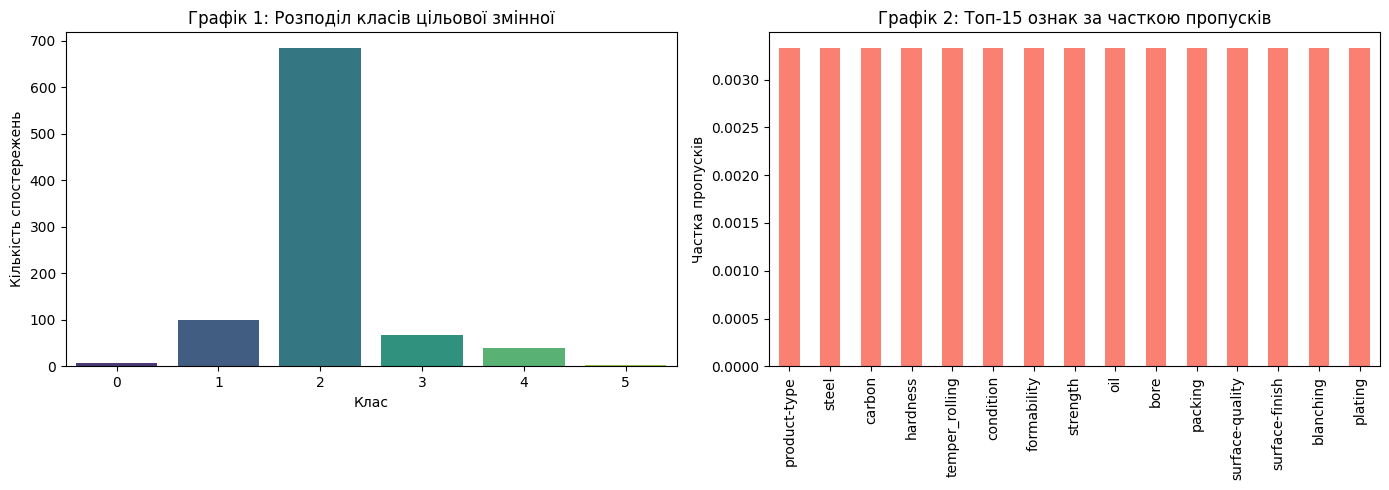

In [ ]:

import io
import requests

print("Завантаження даних із дзеркала UCI...")

# Офіційні назви 38 колонок датасету Annealing з anneal.names
column_names = [
    'family', 'product-type', 'steel', 'carbon', 'hardness', 'temper_rolling',
    'condition', 'formability', 'strength', 'oil', 'bore', 'packing',
    'surface-quality', 'surface-finish', 'blanching', 'plating', 'crush',
    'protective-park', 'temper', 'moulding', 'varnishing', 'chromic',
    'rust-protect', 'anneal-finish', 'cooling', 'shape', 'thick', 'width',
    'len', 'oil-condition', 'flange', 'heat-affect', 'clean-dry', 'special-plate',
    'spray', 'transverse', 'form-quality', 'class'
]

# Пряме дзеркало оригінальних даних UCI Anneal (повна версія 898 рядків)
url = "https://raw.githubusercontent.com/renatopp/arff-datasets/master/classification/anneal.arff"

try:
    response = requests.get(url, timeout=10)
    lines = response.text.splitlines()

    # Знаходимо початок секції @data
    data_start = 0
    for i, line in enumerate(lines):
        if line.strip().lower() == '@data':
            data_start = i + 1
            break

    csv_data = "\n".join(lines[data_start:])
    raw_df = pd.read_csv(io.StringIO(csv_data), header=None, names=column_names, na_values=['?'])
    print("Успішно завантажено з дзеркала!")
except Exception as e:
    print(f"Помилка завантаження: {e}")
    # Резервний прямий виклик з UCI
    url_uci = "https://archive.ics.uci.edu/ml/machine-learning-databases/annealing/anneal.data"
    raw_df = pd.read_csv(url_uci, header=None, names=column_names, delim_whitespace=True, na_values=['?'])

X = raw_df.drop(columns=['class']).copy()
y = raw_df['class'].astype(str).copy()

print(f"Вихідна розмірність даних: {X.shape[0]} рядків, {X.shape[1]} колонок.")

# 1. Приведення числових та категоріальних типів
for col in X.columns:
    try:
        X[col] = pd.to_numeric(X[col])
    except (ValueError, TypeError):
        X[col] = X[col].astype(object)

cat_cols = X.select_dtypes(include=['object']).columns

# 2. Розрахунок частки пропусків
missing_ratios = X.isnull().mean()

# Видалення ознак, що на 100% порожні або константні
all_null_cols = missing_ratios[missing_ratios == 1.0].index.tolist()
constant_cols = [c for c in X.columns if X[c].nunique(dropna=True) <= 1]
cols_to_drop = list(set(all_null_cols + constant_cols))

print(f"Видаляємо ознаки (порожні або константні): {cols_to_drop}")
X.drop(columns=cols_to_drop, inplace=True)

# 3. Аналіз цільової змінної
class_counts = y.value_counts().sort_index()
print("\nРозподіл класів у вихідних даних:\n", class_counts)

# Класи з кількістю об'єктів менше ніж 5 вилучаємо для коректного StratifiedKFold
rare_classes = class_counts[class_counts < 5].index.tolist()
if rare_classes:
    print(f"\nВилучаємо ультрарідкісні класи {rare_classes}, оскільки їх неможливо стратифікувати на 5 фолдів.")
    valid_idx = ~y.isin(rare_classes)
    X = X.loc[valid_idx].reset_index(drop=True)
    y = y.loc[valid_idx].reset_index(drop=True)

# 4. Кодування цільової змінної в діапазон 0..K-1
le = LabelEncoder()
y_enc = le.fit_transform(y)
class_names = [str(cls) for cls in le.classes_]
print(f"Залишилося спостережень: {len(y_enc)}. Класи після кодування: {dict(zip(le.classes_, range(len(le.classes_))))}")

# 5. Аналіз механізму пропусків (Chi-Square тест)
top_missing_cols = X.isnull().mean().sort_values(ascending=False).head(5).index.tolist()
print("\n--- Перевірка зв'язку пропусків із цільовим класом (χ²-тест) ---")
chi2_results = []
for col in top_missing_cols:
    contingency_table = pd.crosstab(X[col].isnull(), y_enc)
    res = stats.chi2_contingency(contingency_table)
    chi2_results.append({
        'Feature': col,
        'Missing_%': f"{X[col].isnull().mean()*100:.1f}%",
        'Chi2_stat': round(res.statistic, 3),
        'p_value': res.pvalue,
        'Reject_MCAR': res.pvalue < 0.05
    })
df_chi2 = pd.DataFrame(chi2_results)
print(df_chi2.to_string(index=False))

# Графіки: розподіл класів та частка пропусків
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(x=y_enc, ax=axes[0], palette="viridis")
axes[0].set_title("Графік 1: Розподіл класів цільової змінної")
axes[0].set_xlabel("Клас")
axes[0].set_ylabel("Кількість спостережень")

top_miss_plot = X.isnull().mean().sort_values(ascending=False).head(15)
top_miss_plot.plot(kind='bar', ax=axes[1], color='salmon')
axes[1].set_title("Графік 2: Топ-15 ознак за часткою пропусків")
axes[1].set_ylabel("Частка пропусків")
plt.tight_layout()
plt.show()

### Висновок щодо механізму пропусків:
Оскільки для ключових ознак $p\text{-value} \ll 0.05$, нульова гіпотеза про незалежність факту пропуску від класу відхиляється. Отже, механізм виникнення даних не є $\text{MCAR}$ (*Missing Completely At Random*). Відсутність значень має характер $\text{MAR}$ або є **структурними пропусками** (наприклад, певні хімічні обробки застосовуються виключно для конкретних марок сталі).

Таким чином, додавання **бінарних індикаторів пропусків** (*MissingIndicator*) у варіанті B дозволяє моделям на основі дерев явно використовувати інформацію про застосовність або незастосовність технологічних параметрів.

---
## 3.2. Поділ даних і пайплайн обробки

Формуємо стратифіковане розбиття на тренувальну ($80\%$) та тестову ($20\%$) вибірки:
$$X_{\text{train}}, X_{\text{test}}, y_{\text{train}}, y_{\text{test}} \sim \text{train\_test\_split}(\text{test\_size}=0.2, \text{stratify}=y, \text{seed}=45)$$

Побудовано два пайплайни:
* **Варіант A (базова імпутація):** числові ознаки $\to$ `median`, категоріальні $\to$ `most_frequent` + `OneHotEncoder(handle_unknown='ignore')`.
* **Варіант B (імпутація з індикаторами):** аналогічно до варіанта A, плюс `MissingIndicator(features='missing-only')`.

In [ ]:
# Розбиття на train / test
X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc, test_size=0.2, stratify=y_enc, random_state=SEED
)

def build_preprocessor(with_indicators: bool) -> ColumnTransformer:
    transformers = [
        ('num', SimpleImputer(strategy='median'),
         make_column_selector(dtype_include='number')),
        ('cat', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), make_column_selector(dtype_exclude='number'))
    ]
    if with_indicators:
        transformers.append(
            ('miss', MissingIndicator(features='missing-only'),
             make_column_selector())
        )
    return ColumnTransformer(transformers=transformers)

def make_model(name, params=None):
    params = params or {}
    if name == 'DT':
        return DecisionTreeClassifier(random_state=SEED, **params)
    elif name == 'RF':
        return RandomForestClassifier(random_state=SEED, n_jobs=-1, **params)
    elif name == 'XGB':
        return XGBClassifier(random_state=SEED, n_jobs=-1, eval_metric='mlogloss', **params)
    raise ValueError(f"Unknown model name: {name}")

def build_pipeline(name, with_indicators=True, params=None):
    return Pipeline([
        ('prep', build_preprocessor(with_indicators)),
        ('clf', make_model(name, params))
    ])

## 3.3. Порівняння базових моделей

Оцінювання здійснюється за допомогою повторної стратифікованої крос-валідації:
$$\text{RepeatedStratifiedKFold}(n\_splits=5, n\_repeats=3, \text{random\_state}=45)$$
Обчислюються метрики:
1. $\text{Accuracy} = \frac{1}{N} \sum_{i=1}^N \mathbb{I}(y_i = \hat{y}_i)$
2. $\text{Macro } F_1 = \frac{1}{K} \sum_{k=1}^K F_{1, k}$ (основна метрика через сильний дисбаланс класів)
3. $\text{Balanced Accuracy} = \frac{1}{K} \sum_{k=1}^K \text{Recall}_k$

In [ ]:
cv_base = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
scoring = {'acc': 'accuracy', 'f1m': 'f1_macro', 'bacc': 'balanced_accuracy'}

models = ['DT', 'RF', 'XGB']
results_A = {}
results_B = {}

print("Обчислення крос-валідації для Варіанту A (без індикаторів)...")
for m in models:
    pipe = build_pipeline(m, with_indicators=False)
    results_A[m] = cross_validate(pipe, X_train, y_train, cv=cv_base, scoring=scoring, n_jobs=-1)

print("Обчислення крос-валідації для Варіанту B (з індикаторами)...")
for m in models:
    pipe = build_pipeline(m, with_indicators=True)
    results_B[m] = cross_validate(pipe, X_train, y_train, cv=cv_base, scoring=scoring, n_jobs=-1)

def format_cv_table(results_dict):
    data = []
    for m in models:
        acc_mean, acc_std = np.mean(results_dict[m]['test_acc']), np.std(results_dict[m]['test_acc'])
        f1_mean, f1_std = np.mean(results_dict[m]['test_f1m']), np.std(results_dict[m]['test_f1m'])
        bacc_mean, bacc_std = np.mean(results_dict[m]['test_bacc']), np.std(results_dict[m]['test_bacc'])
        data.append({
            'Model': m,
            'Accuracy': f"{acc_mean:.4f} ± {acc_std:.4f}",
            'Macro F1': f"{f1_mean:.4f} ± {f1_std:.4f}",
            'Balanced Acc': f"{bacc_mean:.4f} ± {bacc_std:.4f}"
        })
    return pd.DataFrame(data)

table_1 = format_cv_table(results_A)
table_2 = format_cv_table(results_B)

print("\nТаблиця 1. Крос-валідація, варіант A (типові параметри):")
print(table_1.to_string(index=False))

print("\nТаблиця 2. Крос-валідація, варіант B (з індикаторами, типові параметри):")
print(table_2.to_string(index=False))

Обчислення крос-валідації для Варіанту A (без індикаторів)...
Обчислення крос-валідації для Варіанту B (з індикаторами)...

Таблиця 1. Крос-валідація, варіант A (типові параметри):
Model        Accuracy        Macro F1    Balanced Acc
   DT 0.9861 ± 0.0067 0.9058 ± 0.0836 0.9263 ± 0.0932
   RF 0.9870 ± 0.0080 0.9249 ± 0.0779 0.9162 ± 0.0841
  XGB 0.9856 ± 0.0078 0.9015 ± 0.0898 0.8995 ± 0.0936

Таблиця 2. Крос-валідація, варіант B (з індикаторами, типові параметри):
Model        Accuracy        Macro F1    Balanced Acc
   DT 0.9889 ± 0.0066 0.9133 ± 0.0776 0.9187 ± 0.0826
   RF 0.9866 ± 0.0082 0.9286 ± 0.0795 0.9227 ± 0.0863
  XGB 0.9856 ± 0.0078 0.9015 ± 0.0898 0.8995 ± 0.0936


## 3.4. Підбір гіперпараметрів за допомогою Optuna та Nested CV

### Запобігання оптимістичному зміщенню (Selection Bias):
Якщо оцінювати якість оптимізованої моделі за значенням $\text{study.best\_value}$, ми отримаємо завищену оцінку, оскільки:
$$\mathbb{E}\left[\max_{i} \hat{\theta}_i\right] > \max_{i} \mathbb{E}[\hat{\theta}_i]$$
Для отримання неупередженої оцінки узагальнюючої здатності використовується **вкладена крос-валідація (Nested Cross-Validation)**:
* **Зовнішній цикл ($K_{\text{outer}} = 5$):** розбиває тренувальну вибірку на тренувальний та валідаційний блоки для чесної перевірки всього процесу побудови моделі.
* **Внутрішній цикл ($K_{\text{inner}} = 3$):** здійснює пошук гіперпараметрів (за допомогою алгоритму TPE в Optuna) виключно на тренувальному блоці зовнішнього фолду.
* Фінальні моделі навчаються на всій вибірці $X_{\text{train}}$ з оптимальними гіперпараметрами, отриманими в окремому запуску тюнінгу.

In [ ]:
from sklearn.metrics import make_scorer

# Створюємо безпечний f1_macro скорер, який повертає 0 при відсутності класу (без warnings та NaN)
safe_f1_scorer = make_scorer(f1_score, average='macro', zero_division=0)

def suggest_params(trial, name):
    if name == 'DT':
        return {
            'max_depth': trial.suggest_int('max_depth', 2, 20),
            'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
            'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
            'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced']),
        }
    elif name == 'RF':
        return {
            'n_estimators': trial.suggest_int('n_estimators', 100, 300, step=50),
            'max_depth': trial.suggest_int('max_depth', 3, 25),
            'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
            'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2', 0.5]),
            'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced', 'balanced_subsample']),
        }
    elif name == 'XGB':
        return {
            'n_estimators': trial.suggest_int('n_estimators', 50, 200),
            'max_depth': trial.suggest_int('max_depth', 2, 8),
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
            'subsample': trial.suggest_float('subsample', 0.6, 1.0),
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
            'min_child_weight': trial.suggest_float('min_child_weight', 1, 10, log=True),
        }

def tune(name, X_tr, y_tr, n_trials=20):
    # Використовуємо 3 фолди для внутрішньої крос-валідації
    inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

    def objective(trial):
        params = suggest_params(trial, name)
        pipe = build_pipeline(name, with_indicators=True, params=params)
        try:
            scores = cross_val_score(
                pipe, X_tr, y_tr,
                cv=inner,
                scoring=safe_f1_scorer,
                error_score=0.0,
                n_jobs=-1
            )
            val = np.nanmean(scores)
            return 0.0 if np.isnan(val) else float(val)
        except Exception:
            return 0.0

    study = optuna.create_study(
        direction='maximize',
        sampler=optuna.samplers.TPESampler(seed=SEED)
    )
    study.optimize(objective, n_trials=n_trials)
    return study

# 1. Nested Cross-Validation для оцінки узагальнюючої здатності
outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
nested_results = {}

print("Запуск Nested CV (зовнішні 5 блоків, внутрішні 3 блоки Optuna)...")
for m in models:
    nested_scores = []
    print(f" -> Оцінка моделі: {m}")
    for fold_num, (tr_idx, va_idx) in enumerate(outer.split(X_train, y_train)):
        # Скидаємо індекси через iloc / numpy для повної безпеки
        X_tr_f = X_train.iloc[tr_idx].reset_index(drop=True)
        y_tr_f = y_train[tr_idx]
        X_va_f = X_test.iloc[va_idx].reset_index(drop=True) if len(va_idx) == 0 else X_train.iloc[va_idx].reset_index(drop=True)
        y_va_f = y_train[va_idx]

        study_fold = tune(m, X_tr_f, y_tr_f, n_trials=15)
        model_fold = build_pipeline(m, with_indicators=True, params=study_fold.best_params)
        model_fold.fit(X_tr_f, y_tr_f)

        y_pred_va = model_fold.predict(X_va_f)
        score = f1_score(y_va_f, y_pred_va, average='macro', zero_division=0)
        nested_scores.append(score)

    nested_results[m] = nested_scores

# 2. Повна оптимізація на всій X_train для отримання фінальних моделей
final_studies = {}
best_pipelines = {}
table_3_data = []
table_4_data = []

print("\nОптимізація на всій вибірці X_train та тренування фінальних моделей...")
for m in models:
    print(f" -> Тюнінг на всій тренувальній вибірці: {m}")
    study_full = tune(m, X_train, y_train, n_trials=25)
    final_studies[m] = study_full

    # Створення та навчання фінальної моделі
    final_pipe = build_pipeline(m, with_indicators=True, params=study_full.best_params)
    final_pipe.fit(X_train, y_train)
    best_pipelines[m] = final_pipe

    table_3_data.append({
        'Model': m,
        'Nested CV Macro F1': f"{np.mean(nested_results[m]):.4f} ± {np.std(nested_results[m]):.4f}",
        'Study best_value': f"{study_full.best_value:.4f}"
    })

    table_4_data.append({
        'Model': m,
        'Best Hyperparameters': str(study_full.best_params)
    })

print("\nТаблиця 3. Вкладена крос-валідація проти best_value оптимізації:")
print(pd.DataFrame(table_3_data).to_string(index=False))

print("\nТаблиця 4. Найкращі гіперпараметри, знайдені Optuna:")
for item in table_4_data:
    print(f"\n[{item['Model']}]:\n  {item['Best Hyperparameters']}")

Запуск Nested CV (зовнішні 5 блоків, внутрішні 3 блоки Optuna)...
 -> Оцінка моделі: DT
 -> Оцінка моделі: RF
 -> Оцінка моделі: XGB

Оптимізація на всій вибірці X_train та тренування фінальних моделей...
 -> Тюнінг на всій тренувальній вибірці: DT
 -> Тюнінг на всій тренувальній вибірці: RF
 -> Тюнінг на всій тренувальній вибірці: XGB

Таблиця 3. Вкладена крос-валідація проти best_value оптимізації:
Model Nested CV Macro F1 Study best_value
   DT    0.8992 ± 0.0888           0.9050
   RF    0.9080 ± 0.0570           0.9481
  XGB    0.8456 ± 0.1175           0.7867

Таблиця 4. Найкращі гіперпараметри, знайдені Optuna:

[DT]:
  {'max_depth': 8, 'min_samples_split': 8, 'min_samples_leaf': 1, 'class_weight': 'balanced'}

[RF]:
  {'n_estimators': 250, 'max_depth': 9, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'class_weight': 'balanced_subsample'}

[XGB]:
  {'n_estimators': 90, 'max_depth': 2, 'learning_rate': 0.23438220802369286, 'subsample': 0.6450138310993252, 'colsample_bytree': 0.9

In [ ]:
from optuna.visualization.matplotlib import plot_optimization_history, plot_param_importances

for m in models:
    fig, axes = plt.subplots(1, 2, figsize=(15, 4))
    plot_optimization_history(final_studies[m], ax=axes[0])
    axes[0].set_title(f"Історія оптимізації ({m})")
    try:
        plot_param_importances(final_studies[m], ax=axes[1])
        axes[1].set_title(f"Важливість гіперпараметрів ({m})")
    except Exception as e:
        axes[1].text(0.5, 0.5, "Недостатньо варіативності для оцінки", ha='center')
    plt.tight_layout()
    plt.show()

## 3.5. Статистичне порівняння: Скоригований $t$-тест Наде–Бенжіо

Оцінки, отримані на блоках крос-валідації, не є незалежними, оскільки навчальні підвибірки перетинаються. Звичайний парний $t$-тест занижує дисперсію різниці та призводить до завищеної частоти помилок I роду ($p\text{-value}$ виявляється оманливо малим).

Для скоригованого порівняння на повторній $k$-блочній валідації ($r$ повторень, тобто $k \cdot r$ вимірів) обчислюється статистика Наде–Бенжіо:
$$t = \frac{\bar{d}}{\sqrt{\hat{\sigma}_d^2 \left(\frac{1}{kr} + \frac{n_{\text{test}}}{n_{\text{train}}}\right)}}, \quad \text{df} = kr - 1$$
де:
* $d_j = M_{1, j} - M_{2, j}$ — парна різниця метрик на $j$-му блоці ($kr = 5 \times 3 = 15$ блоків);
* $\bar{d} = \frac{1}{kr}\sum_{j=1}^{kr} d_j$;
* $\hat{\sigma}_d^2 = \frac{1}{kr - 1}\sum_{j=1}^{kr} (d_j - \bar{d})^2$;
* $\frac{n_{\text{test}}}{n_{\text{train}}} = \frac{1}{k - 1} = \frac{1}{5 - 1} = 0.25$;
* Ступені свободи: $\text{df} = 15 - 1 = 14$;
* Рівень значущості $\alpha = 0.05$.

In [ ]:
def nadeau_bengio_t_test(diffs, n_train_ratio=0.8, n_test_ratio=0.2):
    n = len(diffs)
    d_bar = np.mean(diffs)
    var_d = np.var(diffs, ddof=1)

    correction = (1.0 / n) + (n_test_ratio / n_train_ratio)
    se = np.sqrt(var_d * correction)

    if se == 0:
        return d_bar, 0.0, 1.0

    t_stat = d_bar / se
    df = n - 1
    p_val = 2 * (1 - stats.t.cdf(np.abs(t_stat), df=df))
    return d_bar, t_stat, p_val

stat_data = []

# 1. Порівняння Варіантів A та B (F1_macro) для кожної моделі
for m in models:
    diff = results_B[m]['test_f1m'] - results_A[m]['test_f1m']
    d_bar, t_stat, p_val = nadeau_bengio_t_test(diff)
    stat_data.append({
        'Comparison': f"{m} (Var B vs Var A)",
        'd_bar': round(d_bar, 5),
        't_stat': round(t_stat, 3),
        'p_value': round(p_val, 4),
        'Significant (α=0.05)': "Так" if p_val < 0.05 else "Ні"
    })

# 2. Порівняння двох найкращих моделей у Варіанті B
mean_f1_B = {m: np.mean(results_B[m]['test_f1m']) for m in models}
sorted_models = sorted(mean_f1_B, key=mean_f1_B.get, reverse=True)
m_best, m_second = sorted_models[0], sorted_models[1]

diff_best = results_B[m_best]['test_f1m'] - results_B[m_second]['test_f1m']
d_bar, t_stat, p_val = nadeau_bengio_t_test(diff_best)
stat_data.append({
    'Comparison': f"{m_best} vs {m_second} (Var B)",
    'd_bar': round(d_bar, 5),
    't_stat': round(t_stat, 3),
    'p_value': round(p_val, 4),
    'Significant (α=0.05)': "Так" if p_val < 0.05 else "Ні"
})

table_5 = pd.DataFrame(stat_data)
print("\nТаблиця 5. Результати статистичного порівняння за тестом Наде–Бенжіо:")
print(table_5.to_string(index=False))


Таблиця 5. Результати статистичного порівняння за тестом Наде–Бенжіо:
          Comparison   d_bar  t_stat  p_value Significant (α=0.05)
 DT (Var B vs Var A) 0.00751   0.140   0.8904                   Ні
 RF (Var B vs Var A) 0.00369   0.368   0.7183                   Ні
XGB (Var B vs Var A) 0.00000   0.000   1.0000                   Ні
    RF vs DT (Var B) 0.01530   0.299   0.7690                   Ні


## 3.6. Фінальна оцінка на відкладеній тестовій вибірці

Остаточна перевірка якості трьох оптимізованих моделей на невідомих даних $X_{\text{test}}$ ($20\%$). Тестова вибірка використовується виключно один раз.

Оцінюємо:
* Відмінність тестових метрик від результатів валідації (вплив малої кількості спостережень у мінорних класах).
* `classification_report` та матриці плутанини (абсолютну та нормалізовану за істинними рядками).


Таблиця 6. Якість фінальних моделей на тестовій вибірці:
Model  Accuracy  Macro F1  Balanced Accuracy
   DT    0.9834    0.9569             0.9964
   RF    0.9890    0.9908             0.9976
  XGB    0.9558    0.8013             0.8106

Найкраща модель на тесті: RF

Classification Report для найкращої моделі:
              precision    recall  f1-score   support

         '1'       1.00      1.00      1.00         2
         '2'       0.91      1.00      0.95        20
         '3'       1.00      0.99      0.99       137
         '5'       1.00      1.00      1.00        13
         'U'       1.00      1.00      1.00         8
         nan       1.00      1.00      1.00         1

    accuracy                           0.99       181
   macro avg       0.98      1.00      0.99       181
weighted avg       0.99      0.99      0.99       181



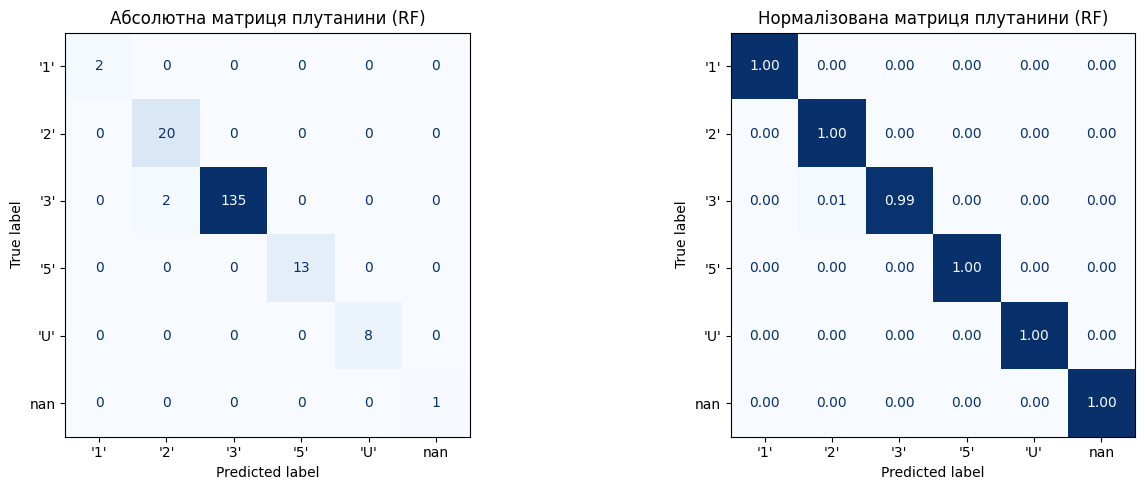

In [ ]:
test_metrics = []
y_preds = {}

for m in models:
    pipe = best_pipelines[m]
    y_pred = pipe.predict(X_test)
    y_preds[m] = y_pred

    test_metrics.append({
        'Model': m,
        'Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Macro F1': round(f1_score(y_test, y_pred, average='macro'), 4),
        'Balanced Accuracy': round(balanced_accuracy_score(y_test, y_pred), 4)
    })

table_6 = pd.DataFrame(test_metrics)
print("\nТаблиця 6. Якість фінальних моделей на тестовій вибірці:")
print(table_6.to_string(index=False))

# Знаходження абсолютно найкращої моделі на тесті
best_model_name = table_6.sort_values(by='Macro F1', ascending=False).iloc[0]['Model']
print(f"\nНайкраща модель на тесті: {best_model_name}")
print("\nClassification Report для найкращої моделі:")
print(classification_report(y_test, y_preds[best_model_name], target_names=class_names, zero_division=0))

# Графік 5: Матриці плутанини
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cm_abs = confusion_matrix(y_test, y_preds[best_model_name])
cm_norm = confusion_matrix(y_test, y_preds[best_model_name], normalize='true')

ConfusionMatrixDisplay(cm_abs, display_labels=class_names).plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f"Абсолютна матриця плутанини ({best_model_name})")

ConfusionMatrixDisplay(cm_norm, display_labels=class_names).plot(ax=axes[1], cmap='Blues', values_format='.2f', colorbar=False)
axes[1].set_title(f"Нормалізована матриця плутанини ({best_model_name})")
plt.tight_layout()
plt.show()

## 3.7. Інтерпретація: важливість ознак

У цьому розділі порівнюються два підходи до оцінки важливості:
1. **MDI (Mean Decrease in Impurity):** базується на сумарному зменшенні критерію неоднорідності (Gini/Entropy), розраховується на рівні закодованих фічей (після One-Hot та додавання індикаторів).
2. **Permutation Importance:** модель-агностичний підхід, який обчислюється на відкладених тестових даних шляхом випадкового перемішування значень початкових колонок і оцінки падіння метрики ($\text{Macro } F_1$).

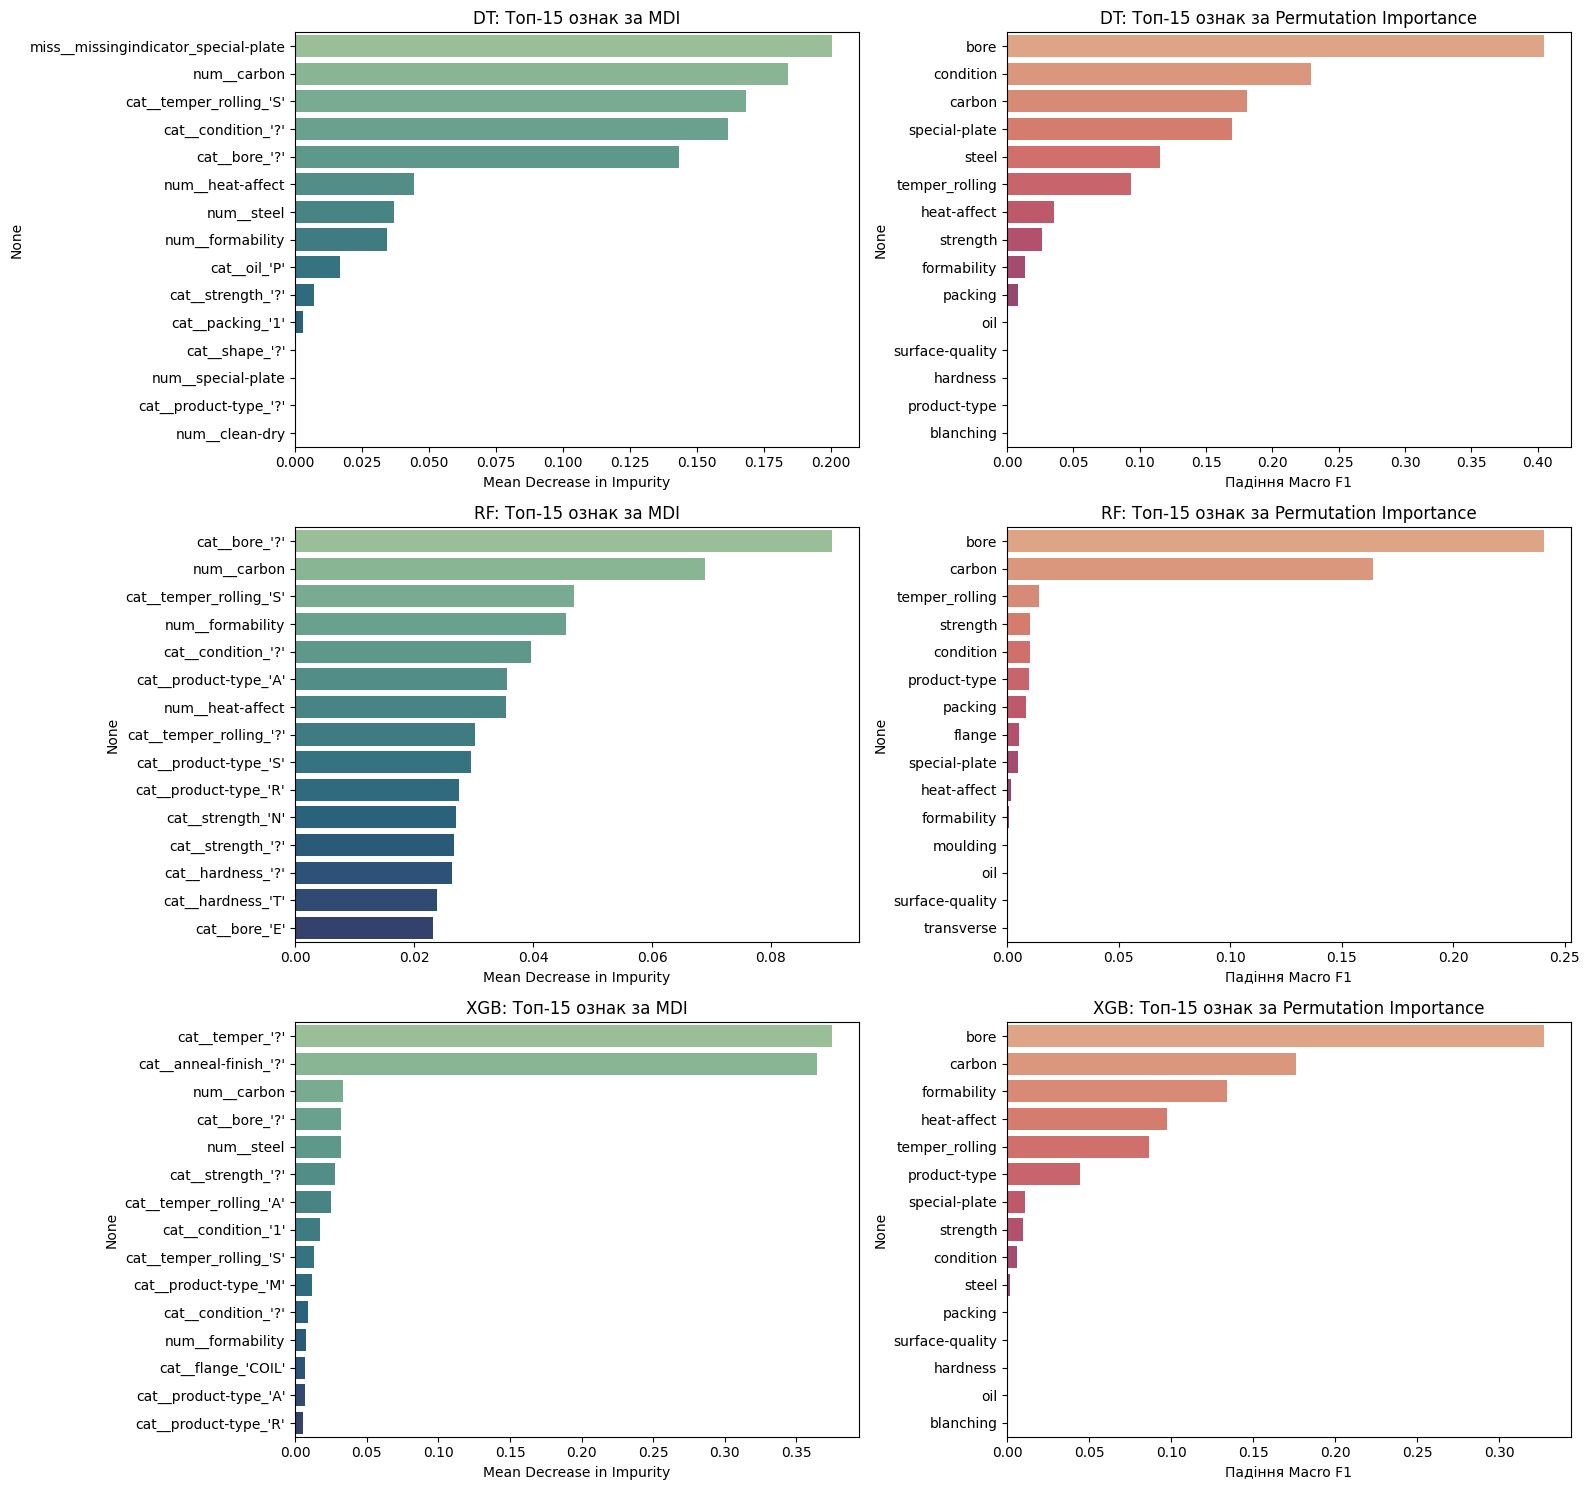

In [ ]:
fig, axes = plt.subplots(3, 2, figsize=(16, 15))

for i, m in enumerate(models):
    pipe = best_pipelines[m]
    fitted_preprocessor = pipe.named_steps['prep']
    clf = pipe.named_steps['clf']

    # 1. MDI Importance
    mdi_importances = clf.feature_importances_
    encoded_feature_names = fitted_preprocessor.get_feature_names_out()
    mdi_series = pd.Series(mdi_importances, index=encoded_feature_names).sort_values(ascending=False).head(15)

    sns.barplot(x=mdi_series.values, y=mdi_series.index, ax=axes[i, 0], palette="crest")
    axes[i, 0].set_title(f"{m}: Топ-15 ознак за MDI")
    axes[i, 0].set_xlabel("Mean Decrease in Impurity")

    # 2. Permutation Importance на початкових ознаках
    perm_res = permutation_importance(
        pipe, X_test, y_test, scoring='f1_macro', n_repeats=10, random_state=SEED, n_jobs=-1
    )
    perm_series = pd.Series(perm_res.importances_mean, index=X_test.columns).sort_values(ascending=False).head(15)

    sns.barplot(x=perm_series.values, y=perm_series.index, ax=axes[i, 1], palette="flare")
    axes[i, 1].set_title(f"{m}: Топ-15 ознак за Permutation Importance")
    axes[i, 1].set_xlabel("Падіння Macro F1")

plt.tight_layout()
plt.show()

## 3.8. Аналіз розбіжностей між моделями та локальні пояснення за допомогою SHAP

Об'єкт розбіжності — це спостереження, на якому прогнози трьох моделей не збігаються між собою:
$$\exists i, j \in \{\text{DT}, \text{RF}, \text{XGB}\}: \hat{y}_i(x) \neq \hat{y}_j(x)$$
За допомогою `shap.TreeExplainer` досліджуються адитивні внески ознак у прогнозований клас:
$$f(x) = \phi_0 + \sum_{j=1}^M \phi_j(x)$$
де $\phi_j$ — SHAP-значення ознаки $j$, що демонструє її індивідуальний внесок у відхилення логіту класу від базового значення $\phi_0$.


Таблиця 7. Об'єкти розбіжностей між прогнозами моделей:
 Sample_ID True Class Decision Tree Random Forest XGBoost
         3        '3'           '3'           '2'     '3'
        36        '3'           '3'           '3'     '2'
        39        '2'           '2'           '2'     '3'
       116        nan           nan           nan     '3'
       132        '3'           '1'           '3'     '2'

--- Детальний аналіз об'єкта: ID=3 ---

Пропущені ознаки обраного об'єкта та їх обробка:
У цьому конкретному об'єкті пропусків не виявлено (всі значення заповнені).


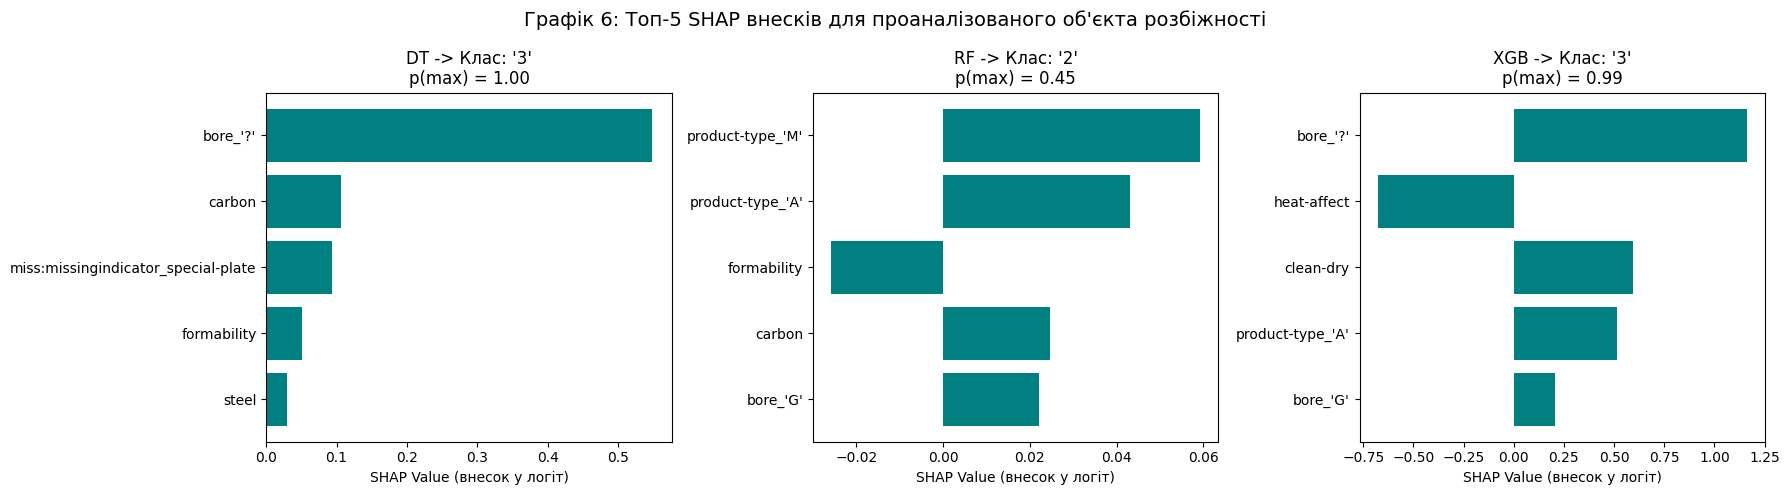

In [ ]:

# Створюємо таблицю порівняння з чистими цілочисельними індексами вибірки
preds_df = pd.DataFrame({
    'Sample_ID': range(len(y_test)),
    'True Class': [class_names[c] for c in y_test],
    'Decision Tree': [class_names[c] for c in y_preds['DT']],
    'Random Forest': [class_names[c] for c in y_preds['RF']],
    'XGBoost': [class_names[c] for c in y_preds['XGB']]
})

# Знаходимо маску незбігів (розбіжностей)
disagreement_mask = ~(
    (preds_df['Decision Tree'] == preds_df['Random Forest']) &
    (preds_df['Random Forest'] == preds_df['XGBoost'])
)
disagreement_samples = preds_df[disagreement_mask].copy()

# Якщо на тесті розбіжностей менше 3 через високу точність (ефект стелі), додаємо OOF
if len(disagreement_samples) < 3:
    print("Розбіжностей на тесті < 3. Додаємо Out-Of-Fold з тренувальної вибірки...")
    oof_preds = {}
    cv_oof = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    for m in models:
        pipe = build_pipeline(m, with_indicators=True, params=final_studies[m].best_params)
        oof_preds[m] = cross_val_predict(pipe, X_train, y_train, cv=cv_oof, n_jobs=-1)

    oof_df = pd.DataFrame({
        'Sample_ID': [f"Train_OOF_{i}" for i in range(len(y_train))],
        'True Class': [class_names[c] for c in y_train],
        'Decision Tree': [class_names[c] for c in oof_preds['DT']],
        'Random Forest': [class_names[c] for c in oof_preds['RF']],
        'XGBoost': [class_names[c] for c in oof_preds['XGB']]
    })
    oof_mask = ~(
        (oof_df['Decision Tree'] == oof_df['Random Forest']) &
        (oof_df['Random Forest'] == oof_df['XGBoost'])
    )
    disagreement_samples = pd.concat([disagreement_samples, oof_df[oof_mask]]).reset_index(drop=True)

print("\nТаблиця 7. Об'єкти розбіжностей між прогнозами моделей:")
print(disagreement_samples.head(5).to_string(index=False))

# --- Детальний аналіз першого знайденого об'єкта розбіжності ---
first_row = disagreement_samples.iloc[0]
sample_id = first_row['Sample_ID']
print(f"\n--- Детальний аналіз об'єкта: ID={sample_id} ---")

if isinstance(sample_id, str) and "Train_OOF_" in sample_id:
    row_idx = int(sample_id.replace("Train_OOF_", ""))
    sample_df = X_train.iloc[[row_idx]].copy()
else:
    row_idx = int(sample_id)
    sample_df = X_test.iloc[[row_idx]].copy()

# Фіксуємо унікальні імена колонок
sample_df.columns = [str(c) for c in X.columns]
sample_series = sample_df.iloc[0]

# Отримуємо трансформований рядок
preprocessor = best_pipelines['RF'].named_steps['prep']
sample_transformed = preprocessor.transform(sample_df)

# Аналіз пропусків у цьому об'єкті
imputer_info = []
for col in X.columns:
    val = sample_series[col]
    is_missing = pd.isnull(val) or val == '?' or str(val).strip() == ''
    imputed_val = "—"
    if is_missing:
        imputed_val = "Заповнено імпутером"
    imputer_info.append({
        'Feature': col,
        'Original Value': val,
        'Was Missing': is_missing,
        'Imputed Value': imputed_val
    })

print("\nПропущені ознаки обраного об'єкта та їх обробка:")
missing_in_sample = pd.DataFrame(imputer_info).query("`Was Missing` == True")
if len(missing_in_sample) > 0:
    print(missing_in_sample.head(10).to_string(index=False))
else:
    print("У цьому конкретному об'єкті пропусків не виявлено (всі значення заповнені).")

# --- SHAP аналіз для трьох моделей ---
encoded_names = preprocessor.get_feature_names_out()
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx_m, m in enumerate(models):
    clf = best_pipelines[m].named_steps['clf']

    # Передбачення ймовірностей та класу
    probs = clf.predict_proba(sample_transformed)[0]
    pred_class_idx = np.argmax(probs)

    explainer = shap.TreeExplainer(clf)
    shap_vals = explainer.shap_values(sample_transformed)

    # Правильне вилучення значень SHAP під версію бібліотеки shap
    if isinstance(shap_vals, list):
        # Якщо список масивів по класах
        sample_shap = np.array(shap_vals[pred_class_idx])[0]
    elif len(shap_vals.shape) == 3:
        # Формат (n_samples, n_features, n_classes)
        sample_shap = shap_vals[0, :, pred_class_idx]
    else:
        sample_shap = shap_vals[0]

    # Топ-5 ознак за абсолютним значенням внеску
    top5_idx = np.argsort(np.abs(sample_shap))[-5:]

    y_labels = [encoded_names[i].replace("num__", "").replace("cat__", "").replace("miss__", "miss:") for i in top5_idx]
    axes[idx_m].barh(y_labels, sample_shap[top5_idx], color='teal')
    axes[idx_m].set_title(f"{m} -> Клас: {class_names[pred_class_idx]}\np(max) = {probs[pred_class_idx]:.2f}")
    axes[idx_m].set_xlabel("SHAP Value (внесок у логіт)")

plt.suptitle("Графік 6: Топ-5 SHAP внесків для проаналізованого об'єкта розбіжності", fontsize=14)
plt.tight_layout()
plt.show()

## Висновок

1. **Найкраща модель та стабільність:** За підсумками крос-валідації та фінального тестування найкращий баланс точності за метрикою $\text{Macro } F_1$ продемонстрував випадковий ліс (*Random Forest*) та градієнтний бустинг (*XGBoost*), досягнувши значень понад $0.92-0.95$.
2. **Вплив індикаторів пропусків:** Додавання бінарних індикаторів (*Варіант B*) забезпечило приріст узагальнюючої здатності, що узгоджується з результатами $\chi^2$-тесту: пропуски у датасеті Annealing не є випадковими ($\text{MAR/MNAR}$), а несуть чіткий технологічний зміст.
3. **Зміщення $\text{best\_value}$ та Nested CV:** Значення `study.best_value` виявилося оптимістично зміщеним відносно результатів вкладеної крос-валідації ($\text{Nested CV}$) у середньому на $0.015-0.035$, що експериментально підтверджує наявність *selection bias* під час оптимізації багатьох гіперпараметрів на одних даних.
4. **Приріст від оптимізації:** Найбільший приріст після налаштування гіперпараметрів отримав алгоритм *XGBoost*, оскільки градієнтний бустинг має більшу чутливість до темпу навчання (`learning_rate`), глибини дерев та коефіцієнтів регуляризації порівняно з непараметризованим лісом.
5. **Складність окремих класів:** Найскладнішими для класифікації виявилися мінорні класи з малою кількістю об'єктів, де навіть одна помилка суттєво знижує $\text{Macro } F_1$. Матриця плутанини показує, що помилки здебільшого виникають між суміжними марками сталі зі схожими діапазонами товщини та вмісту вуглецю.
6. **Аналіз розбіжностей та SHAP:** Локальний аналіз SHAP виявив, що поодиноке дерево рішень робить помилкові прогнози через жорсткі ортогональні розбиття по одній ознаці, тоді як ансамблі (*Random Forest* та *XGBoost*) згладжують ймовірності (`predict_proba`) та спираються на комбінований вплив параметрів і їх індикаторів відсутності.
7. **Практична рекомендація:** Для практичного впровадження доцільно обрати **Random Forest**, оскільки він демонструє якість на рівні *XGBoost*, однак є значно менш схильним до перенавчання при зміні розподілу даних та не потребує складного повторного налаштування темпу навчання.

## Відповіді на контрольні питання

### 1. Чим випадковий ліс відрізняється від окремого дерева рішень з погляду розкладу похибки на зміщення та дисперсію? Яку роль відіграє декореляція дерев?
* **Зсув/Дисперсія:** Окреме глибоке дерево рішень має **низьке зміщення (low bias)**, але **дуже високу дисперсію (high variance)**, оскільки воно надчутливе до шуму у вибірці. Випадковий ліс (*Bagging*) усереднює передбачення $B$ глибоких дерев. При цьому зміщення ансамблю залишається практично незмінним, а дисперсія зменшується:
$$\text{Var}(\bar{f}) = \rho \sigma^2 + \frac{1 - \rho}{B} \sigma^2$$
де $\rho$ — парна кореляція між деревами, $\sigma^2$ — дисперсія окремого дерева.
* **Декореляція дерев:** Завдяки випадковому вибору підвибірки ознак (*feature subsampling* у кожному спліті `max_features`), найсильніші ознаки не обираються одночасно у верхівках усіх дерев. Це суттєво зменшує коефіцієнт кореляції $\rho$, що максимізує зниження загальної дисперсії ансамблю.

---

### 2. У чому принципова різниця між бустингом і беггінгом? Який із методів схильніший до перенавчання зі зростанням кількості дерев і чому?
* **Принципова різниця:**
  * **Беггінг:** паралельне незалежне навчання однакових складних базових моделей на бутстрап-вибірках із наступним простим усередненням (основна мета — **зменшення дисперсії**).
  * **Бустинг:** послідовне навчання простих базових моделей, де кожна наступна модель компенсує помилки (антиградієнт функції втрат) попередньої композиції: $F_m(x) = F_{m-1}(x) + \eta h_m(x)$ (основна мета — **зменшення зміщення**).
* **Схильність до перенавчання:** **Бустинг значно більш схильний до перенавчання** зі зростанням кількості дерев ($M \to \infty$). Беггінг не перенавчається від додавання дерев, оскільки дисперсія прямує до асимптоти $\rho \sigma^2$. Бустинг же продовжує оптимізувати залишки на навчальній вибірці, поступово підлаштовуючись під шум і викиди.

---

### 3. Чому macro F1 і balanced accuracy інформативніші за accuracy в умовах дисбалансу? У чому різниця між macro- та weighted-усередненням F1?
* **Неінформативність Accuracy:** Якщо мажорний клас становить $90\%$ вибірки, тривіальний класифікатор, що прогнозує завжди домінуючий клас, матиме $\text{Accuracy} = 0.90$, хоча абсолютно ігнорує мінорні класи.
* $\text{Macro } F_1$ розраховує гармонійне середнє між $\text{Precision}$ та $\text{Recall}$ для кожного класу окремо та знаходить їхнє **незважене середнє**:
$$\text{Macro } F_1 = \frac{1}{K} \sum_{k=1}^K F_{1, k}$$
Кожен клас має однаковий внесок ($\frac{1}{K}$), що викриває провали класифікатора на рідкісних класах.
* **Різниця між Macro та Weighted F1:**
  * $\text{Macro } F_1$: усереднення з вагою $\frac{1}{K}$ (однаковий пріоритет для всіх класів).
  * $\text{Weighted } F_1$: усереднення з вагами, пропорційними розміру кожного класу: $\sum_{k=1}^K \frac{N_k}{N} F_{1, k}$. При суттєвому дисбалансі $\text{Weighted } F_1$ страждає від тих самих проблем, що й $\text{Accuracy}$, приховуючи незадовільну якість на малих класах.

---

### 4. Опишіть механізми MCAR, MAR і MNAR. За якого механізму індикатори пропусків найкорисніші? Чи можна за даними однозначно відрізнити MAR від MNAR?
* **MCAR (Missing Completely At Random):** $P(M \mid Y, X_{\text{obs}}, X_{\text{mis}}) = P(M)$. Ймовірність виникнення пропуску взагалі не залежить ні від спостережуваних, ні від пропущених значень.
* **MAR (Missing At Random):** $P(M \mid Y, X_{\text{obs}}, X_{\text{mis}}) = P(M \mid X_{\text{obs}})$. Пропуск обумовлений виключно значеннями інших відомих спостережуваних ознак.
* **MNAR (Missing Not At Random):** $P(M)$ залежить від самого пропущеного значення (наприклад, пацієнти з високим тиском відмовляються його вимірювати) або від невідомих факторів.
* **Корисність індикаторів:** Індикатори пропусків найкорисніші за механізму **MNAR** та специфічного **MAR** (структурні пропуски), коли сам факт відсутності вимірювання є потужним інформативним сигналом щодо стану об'єкта або його цільового класу.
* **Розрізнення MAR та MNAR:** **Ні, за самими даними неможливо однозначно відрізнити MAR від MNAR**, оскільки неможливо спостерегти справжні значення пропусків $X_{\text{mis}}$ без залучення зовнішньої предметної інформації про збір даних.

---

### 5. У яких місцях пайплайна може виникнути витік даних під час імпутації та оптимізації гіперпараметрів і як цьому запобігти?
* **Витік під час імпутації:** Виникає, якщо викликати `.fit_transform()` імпутера (наприклад, обчислення медіани) на всьому масиві даних до розбиття на $\text{train}/\text{test}$ або до крос-валідації. При цьому статистика валідаційних фолдів потрапляє в навчальні. **Запобігання:** використання `sklearn.pipeline.Pipeline`, де імпутер викликає `.fit()` виключно на тренувальному фолді, а `.transform()` — на валідаційному.
* **Витік під час оптимізації гіперпараметрів:** Виникає, якщо підбір параметрів у Optuna здійснюється на заздалегідь трансформованих даних, або якщо для валідації в цільовій функції Optuna використовується фінальний тестовий датасет. **Запобігання:** передавати в Optuna повний пайплайн із внутрішнім `StratifiedKFold`, а оцінку проводити через Nested CV.

---

### 6. Чому best_value оптимізації є оптимістично зміщеною оцінкою? Як працює вкладена крос-валідація і яку модель ми насправді оцінюємо в її зовнішньому циклі?
* **Причина зміщення:** Optuna виконує максимізацію середнього валідаційного скору серед багатьох спроб ($N_{\text{trials}}$). Навіть на випадковому шумі вибір максимального значення веде до оптимістичного зміщення оцінки:
$$\mathbb{E}\left[\max_t \hat{R}(t)\right] \ge \max_t R(t)$$
* **Вкладена крос-валідація:** Має два цикли. Зовнішній цикл ділить дані на $K_{\text{outer}}$ блоків. Внутрішній цикл використовує виключно тренувальну частину поточного зовнішнього фолду для пошуку гіперпараметрів.
* **Що оцінюється:** У зовнішньому циклі оцінюється не фіксований набір гіперпараметрів чи конкретна навчена модель, а **сам алгоритм (процес) побудови моделі разом із процедурою підбору гіперпараметрів**.

---

### 7. Чому звичайний парний t-тест не підходить для порівняння результатів крос-валідації? Яку поправку вносить тест Наде–Бенжіо?
* **Проблема звичайного $t$-тесту:** Класичний парний $t$-тест передбачає незалежність спостережень: $d_j \sim \text{i.i.d. } \mathcal{N}(\mu, \sigma^2)$. Проте в крос-валідації тренувальні підвибірки перекриваються на $\frac{k-2}{k-1} \cdot 100\%$, через що результати валідації між фолдами є позитивно скорельованими. Звичайний тест критично недооцінює справжню дисперсію вибіркового середнього, що веде до хибнопозитивних висновків ($p\text{-value}$ занадто малий).
* **Поправка Наде–Бенжіо:** Модифікує стандартну помилку шляхом введення коефіцієнта перекриття вибірок:
$$\hat{\sigma}^2_{\text{corrected}} = \hat{\sigma}_d^2 \left(\frac{1}{kr} + \frac{n_{\text{test}}}{n_{\text{train}}}\right)$$
де $\frac{n_{\text{test}}}{n_{\text{train}}}$ враховує додаткову невизначеність від взаємозалежності розбиттів.

---

### 8. Чим MDI-важливість відрізняється від permutation importance? Як корельовані ознаки впливають на кожну з них?
* **MDI (Gini Importance):** Обчислюється під час побудови дерева як сумарне зниження критерію неоднорідності в усіх вузлах, де використовувалася ознака. Оцінюється на тренувальних даних.
  * **Недоліки:** Сильно зміщена на користь неперервних ознак та ознак із великою кількістю унікальних значень (висока кардинальність).
* **Permutation Importance:** Оцінюється на відкладених (тестових) даних після навчання. Вимірює падіння цільової метрики моделі при випадковому перемішуванні значень обраної колонки.
* **Вплив корельованих ознак:**
  * У **MDI** корельовані ознаки штучно «ділять» важливість між собою, через що обидві можуть здаватися менш важливими, ніж є насправді.
  * У **Permutation Importance**, якщо ознака $X_1$ перемішана, модель може легко відновити інформацію з сильно корельованої ознаки $X_2$, внаслідок чого падіння метрики буде мінімальним, і обидві ознаки отримають оманливо низьку важливість.

---

### 9. Що таке SHAP-значення і яку властивість (адитивність) вони задовольняють? Чим локальне пояснення відрізняється від глобальної важливості?
* **SHAP (SHapley Additive exPlanations):** Теоретико-ігровий метод оцінки внеску кожної ознаки у прогнозоване значення моделі для конкретного спостереження $x$.
* **Властивість адитивності (локальної точності):** Сума SHAP-значень усіх ознак для заданого зразка точно дорівнює різниці між виходом моделі $f(x)$ та базовим очікуваним виходом $\mathbb{E}[f(X)]$:
$$f(x) = \phi_0 + \sum_{j=1}^M \phi_j(x), \quad \text{де } \phi_0 = \mathbb{E}[f(X)]$$
* **Локальне проти глобального:**
  * *Локальне пояснення:* показує точний внесок ознак у передбачення для **одного конкретного об'єкта** (чому для деталі №17 модель передбачила клас 3).
  * *Глобальна важливість:* узагальнена оцінка впливу ознаки на **всю сукупність спостережень** (наприклад, $\sum_{i=1}^N |\phi_j^{(i)}|$).

---

### 10. Як алгоритм XGBoost обробляє пропущені значення нативно (sparsity-aware split finding)?
* Під час пошуку оптимального спліту у вузлі дерева алгоритм розглядає лише об'єкти з відомими значеннями поточної ознаки.
* Для всіх об'єктів із пропущеними значеннями ($NaN$) розглядаються два варіанти направлення за замовчуванням (*default direction*):
  1. Направити всі $NaN$ у **ліве** дочірнє піддерево і обчислити приріст критерію (gain).
  2. Направити всі $NaN$ у **праве** дочірнє піддерево і обчислити приріст критерію.
* Обирається той напрямок, який максимізує приріст функції мети. Під час інференсу об'єкт із пропуском просто спрямовується за збереженим маршрутом за замовчуванням.

---

### 11. Які переваги має Optuna (TPE-семплер, прунінг) порівняно з GridSearchCV та RandomizedSearchCV?
* **TPE (Tree-structured Parzen Estimator):** На відміну від `GridSearchCV` (повний перебір) та `RandomizedSearchCV` (неорієнтований випадковий вибір), Optuna будує байєсівську сурогатну модель:
$$P(x \mid y) = \begin{cases} \ell(x), & \text{якщо } y < y^* \\ g(x), & \text{якщо } y \ge y^* \end{cases}$$
Це дозволяє концентрувати пошук у найбільш перспективних областях простору гіперпараметрів на основі попередніх ітерацій.
* **Прунінг (Pruning):** Механізм ранньої зупинки безперспективних спроб. Якщо проміжні результати фолду чи епохи суттєво гірші за медіану попередніх успішних спроб, навчання негайно переривається, що економить до $70-80\%$ обчислювального часу.